## Part - A 
----------------------

## 1. What are Supervised Learning Algorithms?

Supervised Learning algorithms learn from labeled data, where both input and output values are provided. The model uses this data to learn patterns and make predictions on new data. Regression and Classification are common types of supervised learning.

## 2. Difference between Regression Algorithms and Classification Algorithms
Regression	Classification
Predicts continuous values	Predicts categories or classes
Output is a number	Output is a label
Example: House Price Prediction	Example: Spam Email Detection

## 3. Explain Simple Linear Regression

Simple Linear Regression is a machine learning algorithm used to find the relationship between one independent variable and one dependent variable. It predicts the output using a straight line. It is commonly used when the relationship between variables is linear.

Example: Predicting house price based on house area.

## 4. Assumptions of Linear Regression
There should be a linear relationship between input and output variables.
Errors should be independent of each other.
The variance of errors should remain constant.
The data should not contain extreme outliers.
Independent variables should not be highly correlated.

## 5. What is Bias–Variance Trade-Off?

The Bias–Variance Trade-Off is the balance between underfitting and overfitting. A model with high bias is too simple and may miss important patterns. A model with high variance learns too much from training data and performs poorly on new data. A good model maintains a balance between both.

## 6. Explain Overfitting and Underfitting with Examples
* Overfitting

Overfitting occurs when a model learns the training data too well, including noise and unnecessary details. It performs well on training data but poorly on new data.

Example: Using a very high-degree polynomial model for house price prediction.

* Underfitting

Underfitting occurs when a model is too simple to capture the actual pattern in the data. It performs poorly on both training and testing data.

Example: Using Simple Linear Regression for a highly complex dataset.

## Import library

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## **One-line:**
👉 *Ye libraries data ko load, process, analyze aur visualize karne ke liye use hoti hain.*


## Load Dataset

In [5]:
# Load dataset
df = pd.read_csv("RealEstate_HousePrice_Dataset.csv")

👉 Ye line CSV file ka data read karke Pandas DataFrame me store karti hai, jisse data analysis aasaan ho jata hai.

## Dataset Information

In [6]:
# First 5 rows
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


👉 df.head() dataset ka quick preview dikhata hai taaki data ki structure aur values samajh sakein.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


👉 df.info() dataset ka summary deta hai, jisse data structure aur missing values ka pata chalta hai.

## Missing Values

In [8]:
print("Missing Values\n")

print(df.isnull().sum())

Missing Values

house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64


👉 Ye code dataset ke har column me missing values ki total count check karta hai.

## Statistical Summary

In [35]:
df.describe()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03
mean,102100.500000,1667.357381,3.696667,2.827381,5.611429,23.829524,18.186167,3366.329048,0.642381,0.096190,7.955714,2.364189e+07
std,1212.579894,630.336132,1.574199,1.153585,2.140880,13.945663,8.674549,1658.230565,0.479356,0.294887,7.316766,1.239279e+07
min,100001.000000,450.000000,1.000000,1.000000,1.000000,1.000000,1.000000,800.000000,0.000000,0.000000,0.000000,8.000000e+05
25%,101050.750000,1226.750000,3.000000,2.000000,4.000000,13.000000,11.800000,2122.500000,0.000000,0.000000,2.000000,1.425969e+07
50%,102100.500000,1660.000000,4.000000,3.000000,5.700000,21.000000,17.800000,3188.000000,1.000000,0.000000,6.000000,2.214500e+07
75%,103150.250000,2084.250000,5.000000,4.000000,7.300000,32.000000,24.200000,4364.250000,1.000000,0.000000,12.000000,3.096090e+07
max,104200.000000,4202.000000,7.000000,6.000000,10.000000,80.000000,47.600000,12938.000000,1.000000,1.000000,50.000000,7.611172e+07


👉 df.describe() mean, median, min, max aur quartiles jaise important statistics provide karta hai.

##  Correlation Heatmap

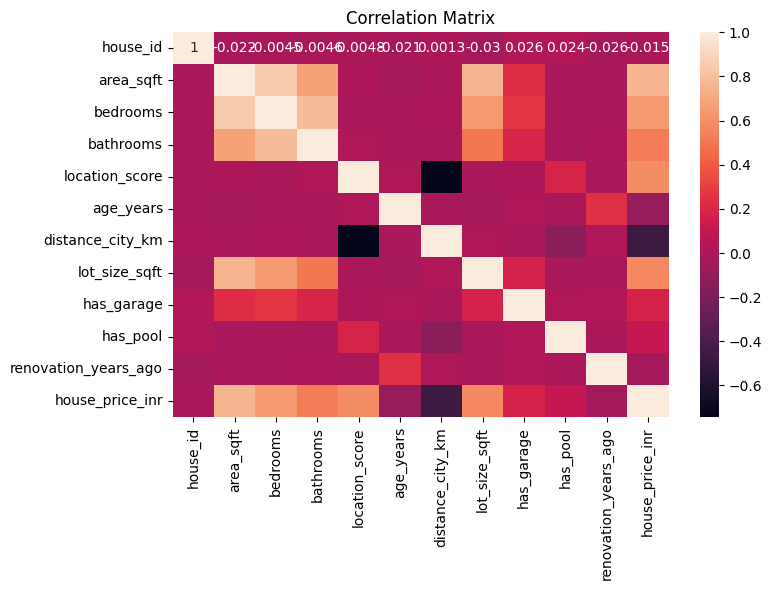

In [10]:
plt.figure(figsize=(8,5))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True
)

plt.title("Correlation Matrix")
plt.show()

👉 Ye heatmap dikhata hai ki dataset ke numerical features ek dusre se kitne strongly related hain.

## Area vs House Price Graph

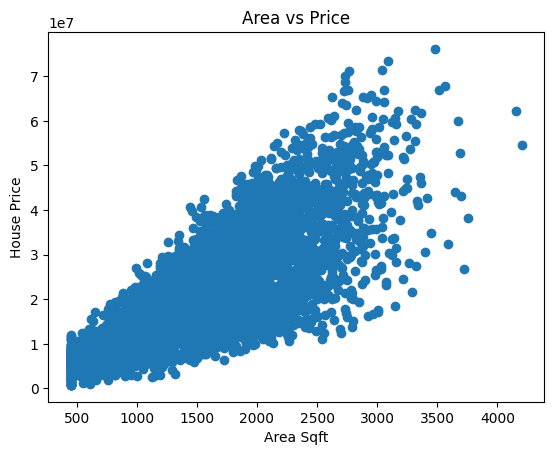

In [11]:
plt.scatter(
    df["area_sqft"],
    df["house_price_inr"]
)
plt.xlabel("Area Sqft")
plt.ylabel("House Price")
plt.title("Area vs Price")
plt.show()

👉 Ye scatter plot dikhata hai ki ghar ka area badhne par house price kaise change hota hai aur dono variables ke beech relationship kya hai.

## Simple Linear Regression
## Train test split 

In [12]:
from sklearn.model_selection import train_test_split
X = df[["area_sqft"]]
y = df["house_price_inr"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training Data :", X_train.shape)
print("Testing Data :", X_test.shape)

Training Data : (3360, 1)
Testing Data : (840, 1)


👉 Ye code dataset ko training (80%) aur testing (20%) data me divide karta hai taaki model ko train aur evaluate kiya ja sake.

## Train Model

In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


👉 Ye code Area aur House Price ke beech relationship seekhkar Linear Regression model train karta hai.

## Slope and Intercept

In [14]:
print("Slope :", model.coef_[0])
print("Intercept :", model.intercept_)

Slope : 14788.306111307533
Intercept : -1163519.1764185987


👉 Slope aur Intercept Linear Regression ki equation ko define karte hain, jisse house price predict kiya jata hai.

## Prediction

In [15]:
y_pred = model.predict(X_test)
print("Predicted Values\n")
print(y_pred[:10])

Predicted Values

[34402357.02127601 27333546.70007102 26771591.06784133 21802720.214442
 31045411.53400921 24287155.64114166 18608446.09439957 37419171.46798275
 27244816.86340317 28043385.39341378]


👉 Ye code trained model ki madad se test data ke house prices predict karta hai.

## Regression Line

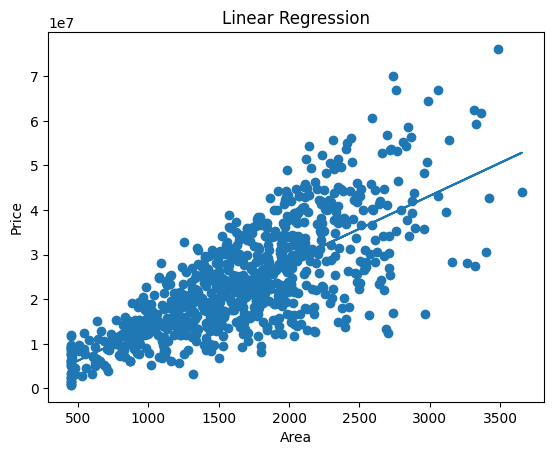

In [16]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred)

plt.xlabel("Area")
plt.ylabel("Price")

plt.title("Linear Regression")
plt.show()

👉 Ye graph actual house prices aur model ki predicted regression line ko compare karke dikhata hai ki model data ko kitni achhi tarah fit kar raha hai.

## Evaluation Metrics
## MAE

In [17]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print("MAE :", mae)

MAE : 6294593.696131912


👉 MAE batata hai ki prediction average me actual value se kitna galat hai; jitna kam MAE, utna achha model.

## MSE

In [18]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
print("MSE :", mse)

MSE : 66989260021849.47


👉 MSE prediction errors ko square karke average nikalta hai, isliye badi mistakes ko zyada penalty milti hai.

## RMSE

In [19]:
rmse = np.sqrt(mse)
print("RMSE :", rmse)

RMSE : 8184696.696997969


👉 RMSE batata hai ki model ki prediction average me actual value se kitni door hai, aur ye original unit me hota hai.

## R² Score

In [20]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("R2 Score :", r2)

R2 Score : 0.5625199587991578


👉 R² Score batata hai ki model target variable ki variability ka kitna percentage explain kar raha hai; 1 ke jitna kareeb ho, utna achha model.

## Adjusted R² Score

In [21]:
# Adjusted R2 Score

n = len(y_test)          # total rows
p = X_test.shape[1]      # total features

adj_r2 = 1 - (
    (1 - r2) * (n - 1)
    / (n - p - 1)
)
print("Adjusted R2 Score :",
      adj_r2)

Adjusted R2 Score : 0.5619979062440257


👉 Adjusted R² Score model ki performance ko measure karta hai aur unnecessary features ke liye penalty bhi lagata hai, isliye ye R² se zyada reliable hota hai.

## Multiple Linear Regression
## Train model

In [22]:
from sklearn.linear_model import LinearRegression

X = df.drop(
    ["house_id", "house_price_inr"],
    axis=1
)

y = df["house_price_inr"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


👉 Ye code Multiple Linear Regression model train karta hai jo house price predict karne ke liye ek se zyada features ka use karta hai.

## Prediction

In [23]:
multi_pred = multi_model.predict(X_test)
print(multi_pred[:10])

[39041695.88003902 31356206.88019851 16525771.65900366 31626148.07085448
 21121327.9064745  29025688.96041952  8369080.53145014 41435037.43278065
 20131804.07726054 41805989.7626556 ]


👉 Ye code trained Multiple Linear Regression model ki madad se test houses ke prices predict karta hai.

## Accuracy

In [ ]:
score = r2_score(
    y_test,
    multi_pred
)

print("R2 Score :", score)

R2 Score : 0.9177606877509896


👉 Ye code check karta hai ki Multiple Linear Regression model house price ki variability ko kitni achhi tarah explain kar raha hai.

## Polynomial Regression
## Polynomial Features


In [25]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
    degree=2
)
X_poly = poly.fit_transform(
    df[["area_sqft"]]
)

print(X_poly[:5])

[[1.000000e+00 1.973000e+03 3.892729e+06]
 [1.000000e+00 1.560000e+03 2.433600e+06]
 [1.000000e+00 2.071000e+03 4.289041e+06]
 [1.000000e+00 2.640000e+03 6.969600e+06]
 [1.000000e+00 1.498000e+03 2.244004e+06]]


👉 Ye code simple area feature ko polynomial features (Area², etc.) me convert karta hai taaki model non-linear relationships bhi seekh sake.

## Train Polynomial Model

In [26]:
poly_model = LinearRegression()

poly_model.fit(
    X_poly,
    y
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


👉 Ye code polynomial features aur house price ke beech non-linear relationship ko learn karne ke liye model train karta hai.

## Prediction Score

In [27]:
poly_pred = poly_model.predict(X_poly)

poly_r2 = r2_score(
    y,
    poly_pred
)

print("Polynomial R2 :", poly_r2)

Polynomial R2 : 0.570839297345231


👉 Ye code check karta hai ki Polynomial Regression model data ko kitni achhi tarah fit kar raha hai aur house price ki variability ko kitna explain kar raha hai.

## Gradient Descent

In [28]:
x = df["area_sqft"].values
y = df["house_price_inr"].values

m = 0
b = 0
lr = 0.00000001

for i in range(1000):
    y_pred = m*x + b
    dm = (-2/len(x)) * np.sum(
        x*(y-y_pred)
    )
    db = (-2/len(x)) * np.sum(
        y-y_pred
    )

    m = m - lr*dm
    b = b - lr*db

print("Slope :", m)
print("Intercept :", b)

Slope : 14263.395276489347
Intercept : 4.679087504821976


👉 Ye code Gradient Descent algorithm ka use karke slope aur intercept ko baar-baar update karta hai taaki prediction error minimum ho jaye.

## Bias Variance & Model Diagnostics
## Residuals Calculate

In [29]:
# Actual - Predicted

residuals = y_test - multi_pred
print(residuals.head())

1743   -2.150710e+06
2196   -3.519367e+06
1728   -1.204238e+06
3337   -8.133741e+05
298    -2.926493e+06
Name: house_price_inr, dtype: float64


👉 Residuals batate hain ki model ki prediction actual value se kitni aur kis direction me galat hai.

## Residual Distribution Plot

c:\Users\jines\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


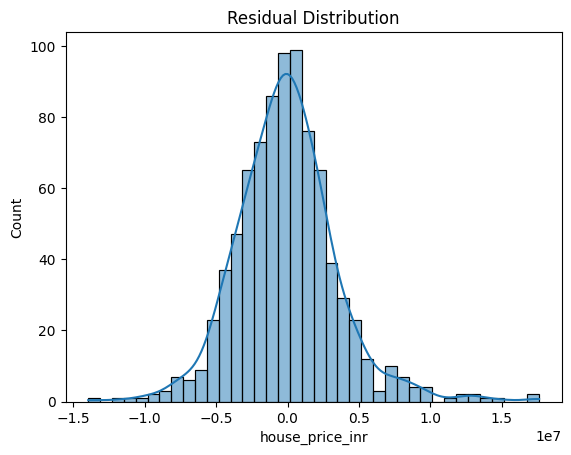

In [30]:
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

👉 Ye graph check karta hai ki residuals (errors) normal distribution ke aas-paas hain ya nahi, jo ek achhe regression model ka indicator hota hai.

## Residual Scatter Plot

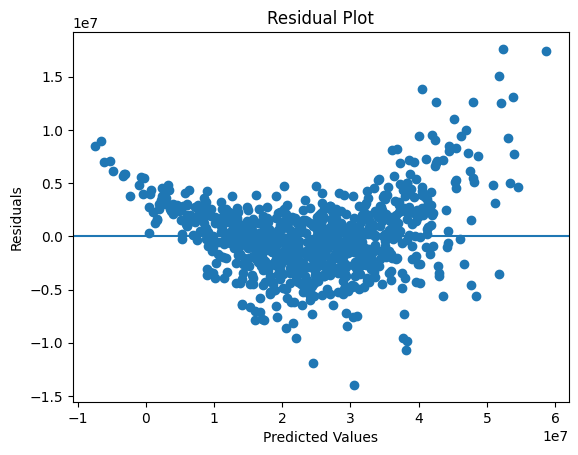

In [31]:
plt.scatter(
    multi_pred,
    residuals
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")
plt.axhline(y=0)

plt.show()

👉 Residual Plot check karta hai ki errors random hain ya nahi; agar points zero line ke aas-paas randomly scattered hon, to model achha fit mana jata hai.

## Train Score vs Test Score

In [32]:
train_score = multi_model.score(
    X_train,
    y_train
)

test_score = multi_model.score(
    X_test,
    y_test
)

print("Train Score :", train_score)

print("Test Score :", test_score)

Train Score : 0.9247216651865339
Test Score : 0.9177606877509896


👉 Train Score aur Test Score ko compare karke pata chalta hai ki model achha generalize kar raha hai ya Overfitting/Underfitting ho raha hai.

## Overfitting / Underfitting Check

In [33]:
difference = abs(
    train_score - test_score
)

print("Difference :", difference)

if difference < 0.10:
    print("Model is Good Fit")

elif train_score > test_score:
    print("Model may be Overfitting")

else:
    print("Model may be Underfitting")

Difference : 0.006960977435544247
Model is Good Fit


👉 Ye code Train aur Test performance compare karke batata hai ki model Good Fit, Overfitting ya Underfitting me se kis condition me hai.

## Final Model Comparison

In [34]:
print("Simple Linear R2 :", r2)
print("Multiple Linear R2 :",
      score)
print("Polynomial R2 :",
      poly_r2)

Simple Linear R2 : 0.5625199587991578
Multiple Linear R2 : 0.9177606877509896
Polynomial R2 : 0.570839297345231


👉 Ye code teenon models (Simple, Multiple aur Polynomial Regression) ki performance compare karta hai taaki sabse achha model identify kiya ja sake.